## Bout durations

Computes and plots bout durations for all fish from segmented speed data. 

Figure S4b : Bout duration for each fish as a function of age. It is computed
as the expected duration of the swimming period for a given time during which the fish is swimming. 

Saved to the project `figures/` directory and to `bout_durations/media/`.

Import libraries:

In [2]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
# Ensure project code dir is on path, then use central path config
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import SPEED_SEGMENTED_DIR, FIGURES_DIR, notebook_media_dir
path = str(SPEED_SEGMENTED_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("bout_durations"))

%load_ext autoreload
%autoreload 2
from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
from functions.brain_analysis import *
from functions.utilities import *
from functions.freely_swimming import *

import os
import h5py
from ipywidgets import interact, IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# path and path_media set in first cell via paths.SPEED_SEGMENTED_DIR and media_dir()

In [4]:
# path_media created in first cell via media_dir(path)

#### Import data:

In [5]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']

In [6]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']

In [7]:
fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']

In [8]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [9]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [10]:
len(fish_ids)

22

Load:

In [11]:
speed_clean = pd.read_hdf(os.path.join(path, f"speed_clean.h5"), key='df')

In [12]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
thrust_thresholds = pd.read_hdf(os.path.join(path, f"thrust_thresholds.h5"), key='df')

In [14]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [15]:
onsets = pd.read_hdf(os.path.join(path, f"onsets.h5"), key='df')

In [16]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [17]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:03<01:03,  3.03s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:05<00:57,  2.87s/it]

...

 91%|█████████ | 20/22 [00:57<00:06,  3.09s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:00<00:03,  3.06s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:04<00:00,  2.91s/it]


In [18]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:03<01:15,  3.59s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:06<01:04,  3.23s/it]

...

 91%|█████████ | 20/22 [01:08<00:07,  3.63s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:13<00:03,  3.85s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:17<00:00,  3.52s/it]


In [19]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)

 32%|███▏      | 7/22 [00:00<00:00, 34.54it/s]

Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 27_12Jun24_1


100%|██████████| 22/22 [00:00<00:00, 59.00it/s]

Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


In [22]:
@interact(i=(0,len(mean_thrust_c_list)-1,1))
def plot(i=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=50)
    ax.hist(np.log10(mean_thrust_c_list[i]),bins=100,histtype='step',density=True)
    ax.axvline(np.log10(thrust_thr_list[i]),c='k')
    plt.show()

interactive(children=(IntSlider(value=0, description='i', max=21), Output()), _dom_classes=('widget-interact',…

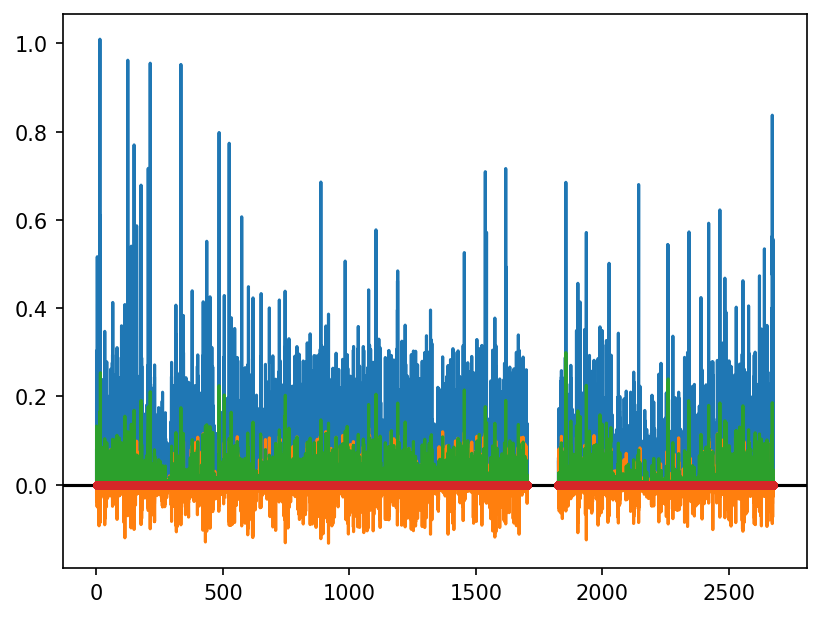

In [23]:
i=13
dt=1/300
default()
inline()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
ax.plot(t_c_list[i],angletail_c_list[i]/10,'-')
ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
ax.axhline(thrust_thr_list[i],c='k')
ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')

plt.show()

In [24]:
i=10
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+t_after)
    ax.plot(t_c_list[i][indices]-t_onset,10*vfish_c_list[i][indices],'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices],'.-',alpha=0.6)
    ax.axvline(bout_duration_list[i][n],c='k')
    ax.set_xlim(-t_before,t_after)
    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=1101), Output()), _dom_classes=('widget-interact…

In [25]:
i=10
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+t_after)
    ax.plot(t_c_list[i][indices]-t_onset,vfish_c_list[i][indices]/1000,'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices]/10000,'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,mean_thrust_c_list[i][indices],'.-',alpha=0.6)
    ax.axvline(bout_duration_list[i][n],c='k')
    ax.axhline(thrust_thr_list[i],c='k')
    ax.set_xlim(-t_before,t_after)
    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=1101), Output()), _dom_classes=('widget-interact…

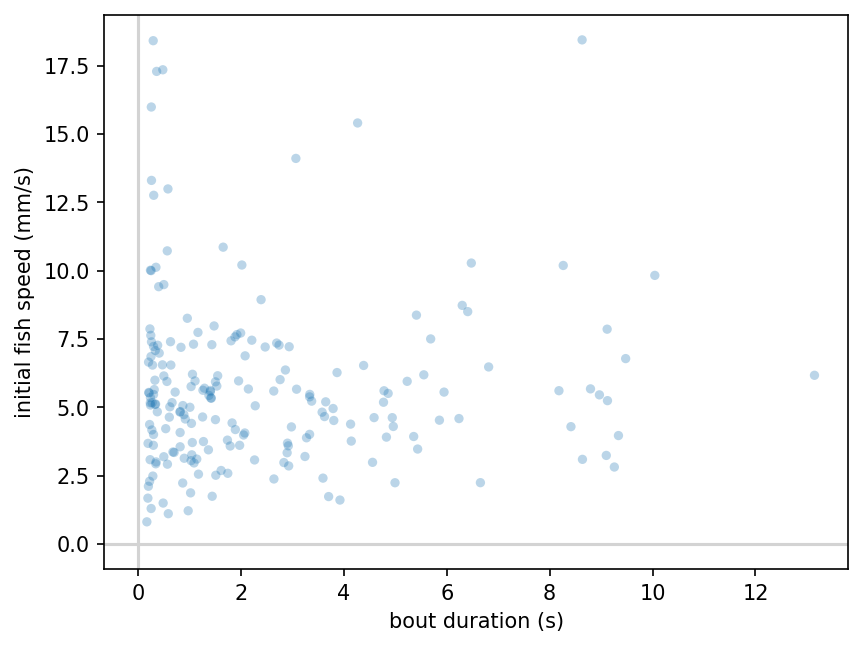

In [26]:
i=1
default()
inline()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.axhline(0,c='lightgray')
ax.axvline(0,c='lightgray')
ax.scatter(bout_duration_list[i],initial_vfish_list[i],s=20,alpha=0.3,edgecolor='none')

ax.set_xlabel('bout duration (s)')
ax.set_ylabel('initial fish speed (mm/s)')

plt.show()

In [27]:
ids_selected=['13_06May24_1',
'13_30Oct24_3',
'13_30Oct24_4',
'14_31Oct24_1',
'17_21May24_2',
'18_22May24_1',
'18_22May24_2',
'19_23May24_5',
'20_05Jun24_1',
'20_05Jun24_2',
'20_12Jun24_1',
'21_06Dec24_1',
'21_06Dec24_2',
'21_06Jun24_1',
'25_10Jun24_1',
'26_02May24_2',
'28_04May24_1',
'30_06May24_2',
'34_11Dec24_1',
'34_11Dec24_3']

In [28]:
len(ids_selected)

20

In [29]:
selected_eta = np.array([0.1267605633802817,
 0.18090452261306533,
 0.16766467065868262,
 0.32323232323232326,
 0.7316491897044805,
 0.41874208526804557,
 0.5468439857086145,
 0.5196718254708186,
 0.19723865877712032,
 0.43912175648702595,
 0.836310011469769,
 0.625154130702836,
 0.5948275862068966,
 0.6583272727272728,
 0.4461122785950165,
 0.8849388379204893,
 0.9033457249070632,
 0.5880829015544041,
 0.8993808049535603,
 0.83])

In [30]:
len(selected_eta)

20

In [31]:
selected_is = [fish_ids.index(x) for x in ids_selected if x in fish_ids]

In [32]:
selected_is

[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21]

#### Compute bout durations:

In [33]:
dt=np.mean(np.diff(t_c_list[0]))
dt

0.003333333333333333

In [34]:
swimming_durations_weighted_mean=np.zeros(len(fish_ids))

for i in range(len(fish_ids)):
    swimming_durations=[]
    for key, group in groupby(mask_movetail_list[i]):
        if key==1:
            swimming_durations.append(len(list(group))*dt)
    
    swimming_durations_weighted_mean[i]=np.average(swimming_durations,weights=swimming_durations)

In [35]:
ages=np.array([int(fish_id[:2]) for fish_id in fish_ids])

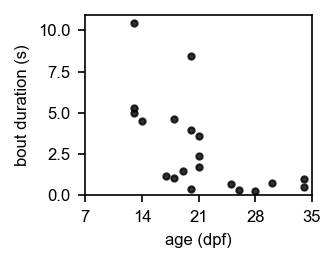

In [37]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.3*textwidthSI,dpi=150)

ax.plot(ages[selected_is],swimming_durations_weighted_mean[selected_is],'k.',alpha=0.8)

ax.set_xlabel(r'age (dpf)')
ax.set_ylabel(r'bout duration (s)')

ax.set_xlim(7,35)
ax.set_ylim(bottom=0)
ax.set_xticks([7,14,21,28,35])

plt.savefig(os.path.join(path_media,f'Fig_S4b_bout_duration_all_fish.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_S4b_bout_duration_all_fish.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()